In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("Customer Segmentation Analysis")
print("All libraries imported successfully!")

Matplotlib is building the font cache; this may take a moment.


Customer Segmentation Analysis
All libraries imported successfully!


In [2]:
df = pd.read_excel("Online Retail.xlsx")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
# Check the number of rows and columns
print("Dataset Shape:", df.shape)

# Display all column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check data types and missing values
print("\nDataset Information:")
df.info()

Dataset Shape: (541909, 8)

Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [4]:
# Count missing values in each column
print("Missing Values:")
print(df.isnull().sum())

# Count duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# Display basic statistics
display(df.describe().T)

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate Rows: 5268


,count,mean,min,25%,50%,75%,max,std
Quantity,541909.0,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,2011-07-04 13:34:57.156386,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303


In [5]:
# Display the first 10 records
display(df.head(10))

# Check the number of unique customers
print(
    "Unique Customers:",
    df["CustomerID"].nunique()
)

# Check the transaction date range
print(
    "Earliest Transaction:",
    df["InvoiceDate"].min()
)

print(
    "Latest Transaction:",
    df["InvoiceDate"].max()
)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047.0,United Kingdom


Unique Customers: 4372
Earliest Transaction: 2010-12-01 08:26:00
Latest Transaction: 2011-12-09 12:50:00


In [6]:
# Create a copy so the original data remains unchanged
df_clean = df.copy()

# Check the original number of rows
print("Rows before cleaning:", len(df_clean))

# Remove duplicate records
df_clean = df_clean.drop_duplicates()

print("Rows after removing duplicates:", len(df_clean))
print("Duplicate rows remaining:", df_clean.duplicated().sum())

Rows before cleaning: 541909
Rows after removing duplicates: 536641
Duplicate rows remaining: 0


In [7]:
# Convert transaction dates to datetime
df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"],
    errors="coerce"
)

# Convert customer IDs to numeric
df_clean["CustomerID"] = pd.to_numeric(
    df_clean["CustomerID"],
    errors="coerce"
)

# Remove rows without customer IDs or valid invoice dates
df_clean = df_clean.dropna(
    subset=["CustomerID", "InvoiceDate"]
)

# Convert customer IDs to integers
df_clean["CustomerID"] = df_clean["CustomerID"].astype(int)

print("Missing customer IDs:", df_clean["CustomerID"].isna().sum())
print("Missing invoice dates:", df_clean["InvoiceDate"].isna().sum())
print("Rows after handling missing values:", len(df_clean))

Missing customer IDs: 0
Missing invoice dates: 0
Rows after handling missing values: 401604


In [8]:
# Remove cancelled invoices, commonly marked with C
df_clean = df_clean[
    ~df_clean["InvoiceNo"].astype(str).str.startswith("C")
].copy()

# Keep only positive quantities and prices
df_clean = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0)
].copy()

# Calculate revenue for each transaction line
df_clean["TotalPrice"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

print("Rows after cleaning:", len(df_clean))
print("Unique customers:", df_clean["CustomerID"].nunique())
print("Total revenue:", round(df_clean["TotalPrice"].sum(), 2))

display(df_clean.head())

Rows after cleaning: 392692
Unique customers: 4338
Total revenue: 8887208.89


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [9]:
print("Final data quality check")
print("------------------------")

print("Missing values:")
print(df_clean.isnull().sum())

print("\nDuplicate rows:", df_clean.duplicated().sum())

print("\nData types:")
print(df_clean.dtypes)

print("\nCleaned dataset shape:", df_clean.shape)

Final data quality check
------------------------
Missing values:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
TotalPrice     0
dtype: int64

Duplicate rows: 0

Data types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID              int64
Country                   str
TotalPrice            float64
dtype: object

Cleaned dataset shape: (392692, 9)


In [10]:
# Find the latest transaction date
latest_date = df_clean["InvoiceDate"].max()

# Set reference date to one day after the latest transaction
reference_date = latest_date + pd.Timedelta(days=1)

print("Latest transaction:", latest_date)
print("Reference date:", reference_date)

Latest transaction: 2011-12-09 12:50:00
Reference date: 2011-12-10 12:50:00


In [11]:
rfm = (
    df_clean.groupby("CustomerID")
    .agg(
        Recency=(
            "InvoiceDate",
            lambda x: (reference_date - x.max()).days
        ),
        Frequency=("InvoiceNo", "nunique"),
        Monetary=("TotalPrice", "sum")
    )
    .reset_index()
)

print("RFM analysis completed!")
print("Total customers:", len(rfm))

display(rfm.head(10))

RFM analysis completed!
Total customers: 4338


,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1797.24
3,12349,19,1,1757.55
4,12350,310,1,334.40
5,12352,36,8,2506.04
6,12353,204,1,89.00
7,12354,232,1,1079.40
8,12355,214,1,459.40
9,12356,23,3,2811.43


In [12]:
print("RFM statistical summary:")
display(rfm[["Recency", "Frequency", "Monetary"]].describe().T)

RFM statistical summary:


,count,mean,std,min,25%,50%,75%,max
Recency,4338.0,92.536422,100.014169,1.00,18.0000,51.00,142.0000,374.00
Frequency,4338.0,4.272015,7.697998,1.00,1.0000,2.00,5.0000,209.00
Monetary,4338.0,2048.688081,8985.230220,3.75,306.4825,668.57,1660.5975,280206.02


In [13]:
top_customers = rfm.sort_values(
    by="Monetary",
    ascending=False
).head(10)

display(top_customers)

,CustomerID,Recency,Frequency,Monetary
1689,14646,2,73,280206.02
4201,18102,1,60,259657.30
3728,17450,8,46,194390.79
3008,16446,1,2,168472.50
1879,14911,1,201,143711.17
55,12415,24,21,124914.53
1333,14156,10,55,117210.08
3771,17511,3,31,91062.38
2702,16029,39,63,80850.84
0,12346,326,1,77183.60


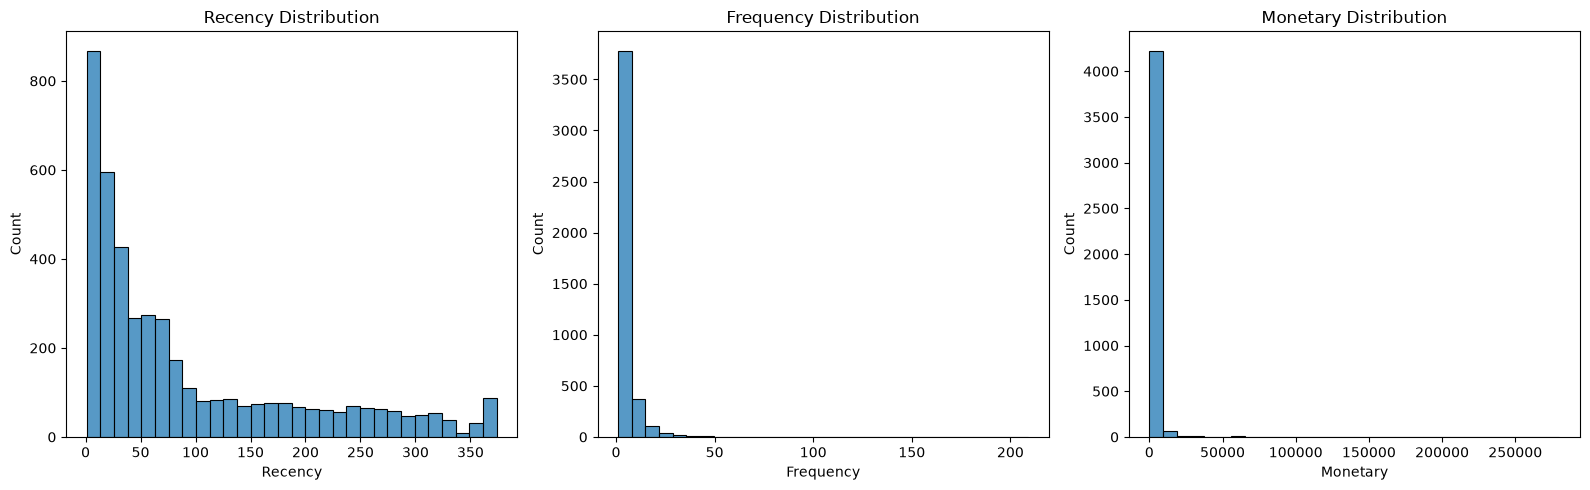

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.histplot(
    data=rfm,
    x="Recency",
    bins=30,
    ax=axes[0]
)
axes[0].set_title("Recency Distribution")

sns.histplot(
    data=rfm,
    x="Frequency",
    bins=30,
    ax=axes[1]
)
axes[1].set_title("Frequency Distribution")

sns.histplot(
    data=rfm,
    x="Monetary",
    bins=30,
    ax=axes[2]
)
axes[2].set_title("Monetary Distribution")

plt.tight_layout()
plt.show()

In [15]:
# Select the RFM features
features = ["Recency", "Frequency", "Monetary"]

# Reduce skewness using log transformation
rfm_log = np.log1p(rfm[features])

# Standardize the transformed features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(rfm_log)

print("Feature scaling completed!")
print("Shape:", X_scaled.shape)

print("\nFirst 5 scaled rows:")
print(X_scaled[:5])

Feature scaling completed!
Shape: (4338, 3)

First 5 scaled rows:
[[ 1.46199281 -0.95521426  3.7077163 ]
 [-2.03873442  1.07442519  1.41490344]
 [ 0.37310424  0.38630445  0.72002428]
 [-0.62308592 -0.95521426  0.70228691]
 [ 1.42455753 -0.95521426 -0.61451388]]


In [16]:
inertias = []

k_values = range(2, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)
    inertias.append(model.inertia_)

print("Inertia values:", inertias)


Inertia values: [6483.589425039297, 4869.488628540217, 3939.0493816391604, 3296.7087076425437, 2855.7640680431095, 2548.820244849563, 2336.341053610392, 2156.0056725213435, 2005.746236269557]


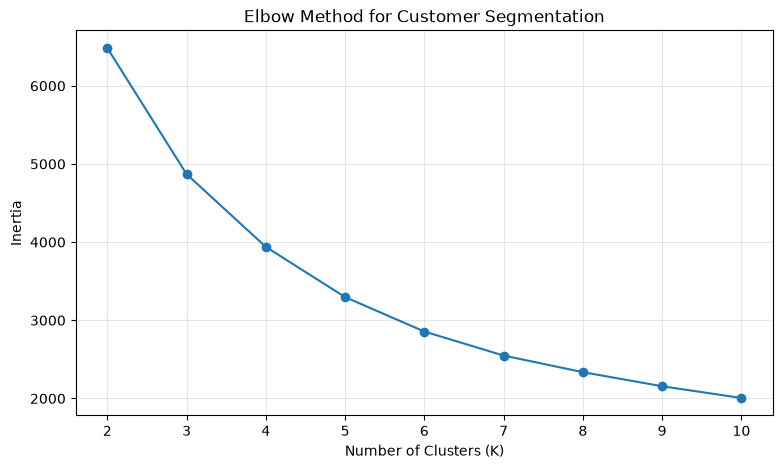

In [17]:
plt.figure(figsize=(9, 5))

plt.plot(
    list(k_values),
    inertias,
    marker="o"
)

plt.title("Elbow Method for Customer Segmentation")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)

plt.show()

In [18]:
silhouette_scores = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels
    )

    silhouette_scores.append(score)

results = pd.DataFrame({
    "K": list(range(2, 11)),
    "Silhouette Score": silhouette_scores
})

display(
    results.sort_values(
        by="Silhouette Score",
        ascending=False
    )
)

,K,Silhouette Score
0,2,0.432827
2,4,0.337517
1,3,0.336517
3,5,0.316200
4,6,0.312409
5,7,0.309186
6,8,0.303275
7,9,0.281085
8,10,0.276659


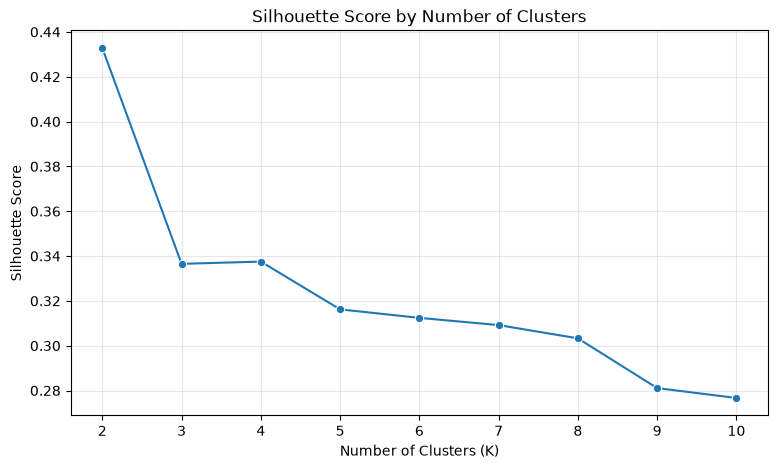

In [19]:
plt.figure(figsize=(9, 5))

sns.lineplot(
    data=results,
    x="K",
    y="Silhouette Score",
    marker="o"
)

plt.title("Silhouette Score by Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(list(range(2, 11)))
plt.grid(True, alpha=0.3)

plt.show()

In [20]:
chosen_k = 4

print("Selected number of clusters:", chosen_k)

Selected number of clusters: 4


In [21]:
kmeans = KMeans(
    n_clusters=chosen_k,
    random_state=42,
    n_init=10
)

# Fit the model and assign cluster labels
rfm["Cluster"] = kmeans.fit_predict(X_scaled)

print("K-Means clustering completed!")
print("\nFirst 10 customers with cluster labels:")

display(rfm.head(10))

K-Means clustering completed!

First 10 customers with cluster labels:


,CustomerID,Recency,Frequency,Monetary,Cluster
0,12346,326,1,77183.60,3
1,12347,2,7,4310.00,0
2,12348,75,4,1797.24,3
3,12349,19,1,1757.55,2
4,12350,310,1,334.40,1
5,12352,36,8,2506.04,3
6,12353,204,1,89.00,1
7,12354,232,1,1079.40,1
8,12355,214,1,459.40,1
9,12356,23,3,2811.43,3


In [22]:
cluster_counts = (
    rfm["Cluster"]
    .value_counts()
    .sort_index()
)

print("Customers in each cluster:")
display(cluster_counts.to_frame(name="Customer_Count"))

Customers in each cluster:


,Customer_Count
Cluster,
0,713
1,1622
2,837
3,1166


In [23]:
cluster_profile = (
    rfm.groupby("Cluster")
    .agg(
        Customer_Count=("CustomerID", "count"),
        Avg_Recency=("Recency", "mean"),
        Avg_Frequency=("Frequency", "mean"),
        Avg_Monetary=("Monetary", "mean"),
        Total_Revenue=("Monetary", "sum")
    )
    .round(2)
)

cluster_profile["Customer_Percentage"] = (
    cluster_profile["Customer_Count"]
    / len(rfm) * 100
).round(2)

display(cluster_profile)

,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Revenue,Customer_Percentage
Cluster,,,,,,
0,713,12.17,13.75,8088.02,5766757.07,16.44
1,1622,181.51,1.32,341.00,553099.77,37.39
2,837,17.70,2.19,557.32,466479.03,19.29
3,1166,71.64,4.08,1801.78,2100873.02,26.88


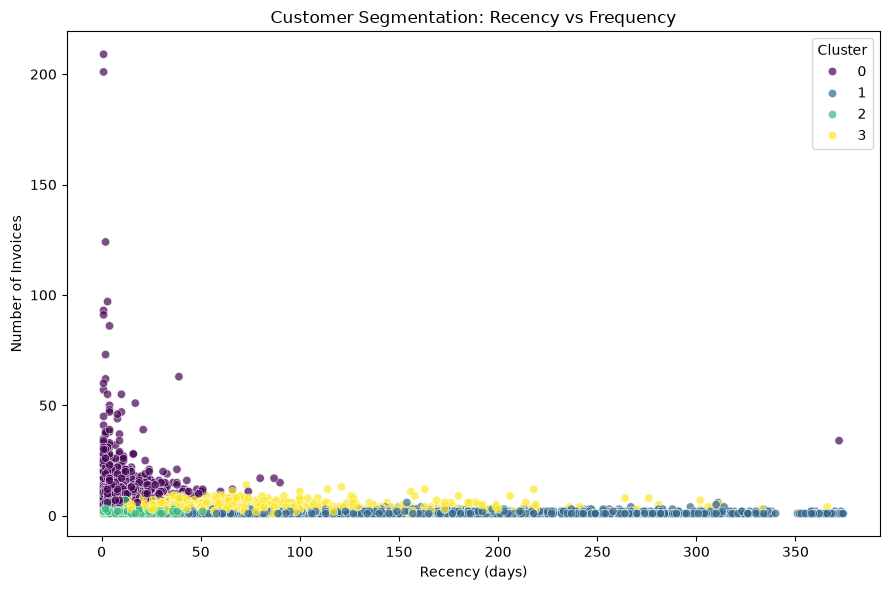

In [24]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=rfm,
    x="Recency",
    y="Frequency",
    hue="Cluster",
    palette="viridis",
    alpha=0.7
)

plt.title("Customer Segmentation: Recency vs Frequency")
plt.xlabel("Recency (days)")
plt.ylabel("Number of Invoices")
plt.tight_layout()
plt.show()

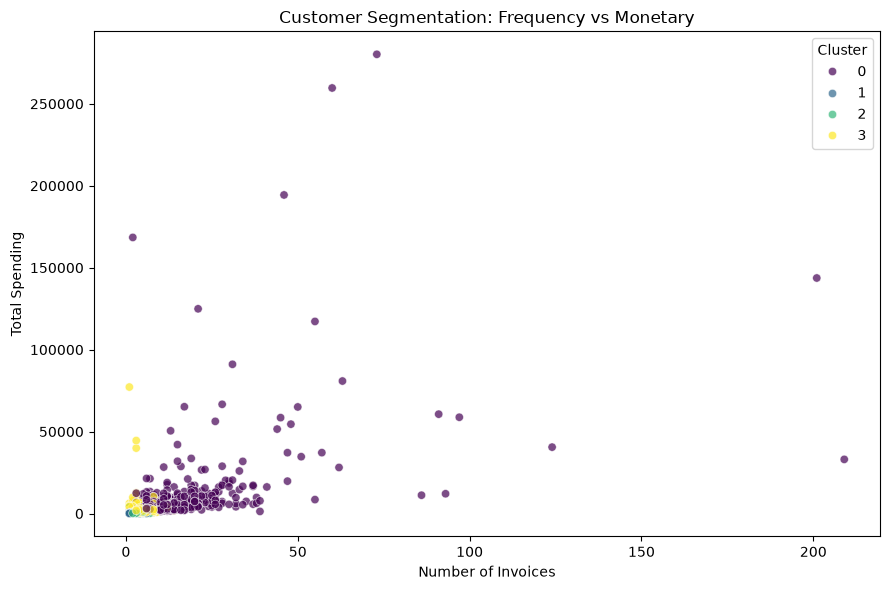

In [25]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=rfm,
    x="Frequency",
    y="Monetary",
    hue="Cluster",
    palette="viridis",
    alpha=0.7
)

plt.title("Customer Segmentation: Frequency vs Monetary")
plt.xlabel("Number of Invoices")
plt.ylabel("Total Spending")
plt.tight_layout()
plt.show()

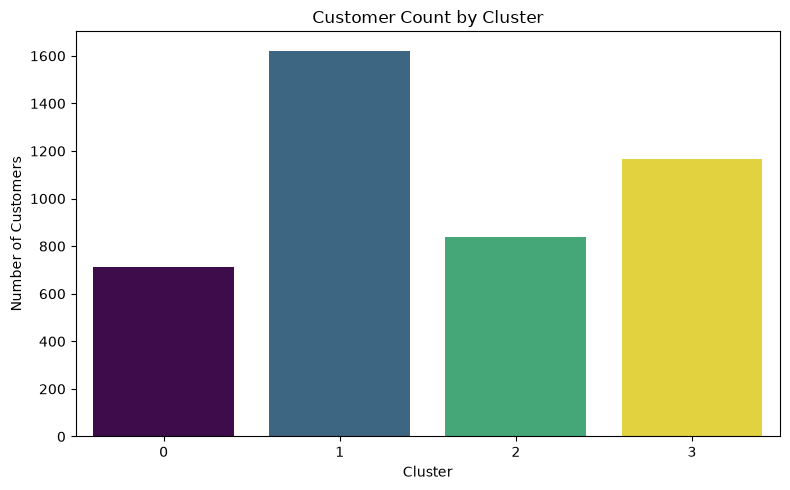

In [26]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=rfm,
    x="Cluster",
    hue="Cluster",
    palette="viridis",
    legend=False
)

plt.title("Customer Count by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

In [27]:
display(cluster_profile)

,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Revenue,Customer_Percentage
Cluster,,,,,,
0,713,12.17,13.75,8088.02,5766757.07,16.44
1,1622,181.51,1.32,341.00,553099.77,37.39
2,837,17.70,2.19,557.32,466479.03,19.29
3,1166,71.64,4.08,1801.78,2100873.02,26.88


In [28]:
overall_avg = rfm[
    ["Recency", "Frequency", "Monetary"]
].mean()

print("Overall customer averages:")
display(overall_avg.to_frame(name="Overall Average"))

print("\nCluster profiles:")
display(cluster_profile)

Overall customer averages:


,Overall Average
Recency,92.536422
Frequency,4.272015
Monetary,2048.688081



Cluster profiles:


,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Revenue,Customer_Percentage
Cluster,,,,,,
0,713,12.17,13.75,8088.02,5766757.07,16.44
1,1622,181.51,1.32,341.00,553099.77,37.39
2,837,17.70,2.19,557.32,466479.03,19.29
3,1166,71.64,4.08,1801.78,2100873.02,26.88


In [29]:
revenue_summary = rfm.groupby("Cluster").agg(
    Customers=("CustomerID", "count"),
    Total_Revenue=("Monetary", "sum")
)

revenue_summary["Revenue_Percentage"] = (
    revenue_summary["Total_Revenue"]
    / revenue_summary["Total_Revenue"].sum()
    * 100
).round(2)

revenue_summary["Customer_Percentage"] = (
    revenue_summary["Customers"]
    / revenue_summary["Customers"].sum()
    * 100
).round(2)

display(revenue_summary.round(2))

,Customers,Total_Revenue,Revenue_Percentage,Customer_Percentage
Cluster,,,,
0,713,5766757.07,64.89,16.44
1,1622,553099.77,6.22,37.39
2,837,466479.03,5.25,19.29
3,1166,2100873.02,23.64,26.88


In [30]:
import os

os.makedirs("outputs", exist_ok=True)

rfm.to_csv(
    "outputs/customer_segments.csv",
    index=False
)

cluster_profile.to_csv(
    "outputs/cluster_profile.csv"
)

revenue_summary.to_csv(
    "outputs/revenue_summary.csv"
)

print("Customer segmentation results exported successfully!")

Customer segmentation results exported successfully!


In [31]:
cluster_names = {
    0: "High-Value Loyal Customers",
    1: "Inactive or Low-Engagement Customers",
    2: "Recent Low-Frequency Customers",
    3: "Regular Mid-Value Customers"
}

rfm["Customer_Segment"] = rfm["Cluster"].map(cluster_names)

display(
    rfm[
        [
            "CustomerID",
            "Recency",
            "Frequency",
            "Monetary",
            "Cluster",
            "Customer_Segment"
        ]
    ].head(10)
)

,CustomerID,Recency,Frequency,Monetary,Cluster,Customer_Segment
0,12346,326,1,77183.60,3,Regular Mid-Value Customers
1,12347,2,7,4310.00,0,High-Value Loyal Customers
2,12348,75,4,1797.24,3,Regular Mid-Value Customers
3,12349,19,1,1757.55,2,Recent Low-Frequency Customers
4,12350,310,1,334.40,1,Inactive or Low-Engagement Customers
5,12352,36,8,2506.04,3,Regular Mid-Value Customers
6,12353,204,1,89.00,1,Inactive or Low-Engagement Customers
7,12354,232,1,1079.40,1,Inactive or Low-Engagement Customers
8,12355,214,1,459.40,1,Inactive or Low-Engagement Customers
9,12356,23,3,2811.43,3,Regular Mid-Value Customers


In [32]:
revenue_summary = rfm.groupby("Customer_Segment").agg(
    Customers=("CustomerID", "count"),
    Total_Revenue=("Monetary", "sum"),
    Average_Spending=("Monetary", "mean")
)

revenue_summary["Revenue_Share_Percent"] = (
    revenue_summary["Total_Revenue"]
    / rfm["Monetary"].sum()
    * 100
).round(2)

display(revenue_summary.round(2))

,Customers,Total_Revenue,Average_Spending,Revenue_Share_Percent
Customer_Segment,,,,
High-Value Loyal Customers,713,5766757.07,8088.02,64.89
Inactive or Low-Engagement Customers,1622,553099.77,341.00,6.22
Recent Low-Frequency Customers,837,466479.03,557.32,5.25
Regular Mid-Value Customers,1166,2100873.02,1801.78,23.64


In [33]:
import os

os.makedirs("outputs", exist_ok=True)

rfm.to_csv("outputs/customer_segments.csv", index=False)
cluster_profile.to_csv("outputs/cluster_profile.csv")
revenue_summary.to_csv("outputs/revenue_summary.csv")

print("All customer segmentation results exported successfully!")

All customer segmentation results exported successfully!


# Customer Segmentation Analysis

## 1. Project Overview
This project uses Python and machine learning to segment e-commerce customers according to their purchasing behavior. The objective is to help businesses understand customer value and develop targeted marketing strategies.

## 2. Problem Statement
Customers differ in purchase frequency, spending, and recency. Treating all customers identically can lead to ineffective marketing. This project applies RFM analysis and K-Means clustering to identify distinct customer groups.

## 3. Technologies Used
- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- Jupyter Notebook

## 4. Dataset
The project uses the UCI Online Retail transaction dataset.

Source: https://archive.ics.uci.edu/dataset/352/online+retail

## 5. Methodology
1. Loaded and inspected transaction data.
2. Cleaned missing values, duplicates, cancelled invoices, and invalid transactions.
3. Calculated Recency, Frequency, and Monetary values.
4. Applied logarithmic transformation and feature standardization.
5. Evaluated cluster counts using the Elbow Method and silhouette scores.
6. Applied K-Means clustering with four clusters.
7. Visualized and profiled customer segments.
8. Calculated customer and revenue contributions.

## 6. Customer Segments
- High-Value Loyal Customers
- Inactive or Low-Engagement Customers
- Recent Low-Frequency Customers
- Regular Mid-Value Customers

## 7. Key Business Insights
- High-Value Loyal Customers contribute approximately 64.89% of total revenue.
- This segment represents approximately 16.44% of customers.
- Inactive or Low-Engagement Customers represent approximately 37.39% of customers and may be suitable for re-engagement campaigns.
- Regular Mid-Value Customers contribute approximately 23.64% of total revenue.
- Recent Low-Frequency Customers may benefit from personalized product recommendations and second-purchase incentives.

## 8. Business Recommendations
- Introduce loyalty rewards for high-value customers.
- Test targeted re-engagement campaigns for inactive customers.
- Encourage recent customers to make repeat purchases.
- Use personalized recommendations to increase customer engagement.
- Monitor segment sizes and revenue contributions over time.

## 9. Conclusion
RFM analysis and K-Means clustering helped identify four customer segments with different purchasing patterns. The results show that a relatively small group of high-value customers contributes a large share of revenue. These insights can help businesses prioritize retention efforts, personalize marketing, and improve customer relationship management.

## 10. Project Outputs
- Customer-level segmentation CSV
- Cluster profile CSV
- Revenue summary CSV
- Exploratory analysis and cluster visualizations
- Jupyter Notebook containing the complete workflow

In [34]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nExported files:")

for filename in [
    "outputs/customer_segments.csv",
    "outputs/cluster_profile.csv",
    "outputs/revenue_summary.csv"
]:
    print(filename, "->", os.path.exists(filename))

Current working directory:
C:\Users\ACER\OneDrive\Desktop\OIBSIP\TASK02

Exported files:
outputs/customer_segments.csv -> True
outputs/cluster_profile.csv -> True
outputs/revenue_summary.csv -> True
